Tehtävä 15
Käytä tehtävän 11 tasavauhtista kävelymittausta.

a) Laske valitun kiihtyvyyskomponentin Fourier-muunnos ja tehospektri.

b) Tunnista hallitseva taajuus ja arvioi, vastaako se askelta vai askelparia.

c) Arvioi askelmäärä taajuuden ja mittausajan avulla.

d) Vertaa tulosta suodatusmenetelmään ja itse laskemaasi askelmäärään.

e) Kirjaa, millaisilla oletuksilla Fourier-menetelmä toimii tässä mittauksessa.

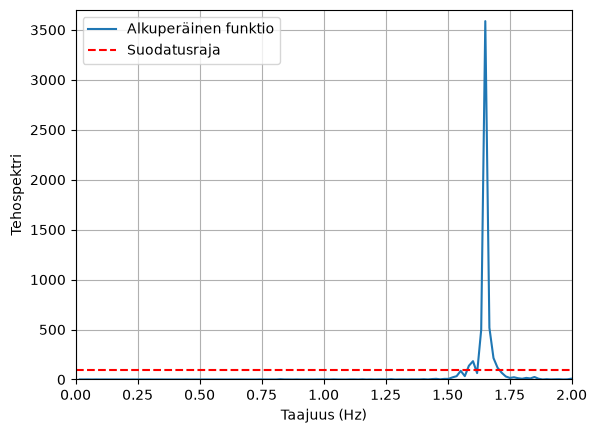

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#a) Laske valitun kiihtyvyyskomponentin Fourier-muunnos ja tehospektri.

#Time (s)	Linear Acceleration x (m/s^2)	Linear Acceleration y (m/s^2)	Linear Acceleration z (m/s^2)	Absolute acceleration (m/s^2)
df = pd.read_csv('./Data/Acceleration_withoutG/walkingData.csv')
t = df['Time (s)']
z_signal = df['Linear Acceleration z (m/s^2)']
N = len(t)
dt = np.median(np.diff(t))

fourier = np.fft.fft(z_signal, N)

psd = fourier*np.conj(fourier)/N

freq = np.fft.fftfreq(N,dt)
L = np.arange(1, np.floor(N/2), dtype='int') #Määritellään ne tehospektrin arvot, joita käytetään
PSD = np.array([freq[L], psd[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD[0,:], PSD[1,:], label="Alkuperäinen funktio")
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
plt.axhline(100, color="red", linestyle="--", label="Suodatusraja")
plt.legend()
plt.grid()
plt.axis([0,2,0,3700])
plt.show()

In [ ]:
#b) Tunnista hallitseva taajuus ja arvioi, vastaako se askelta vai askelparia.
#taajuus n. 1.7Hz vastaa yhtä askelta

#c) Arvioi askelmäärä taajuuden ja mittausajan avulla.
#d) Vertaa tulosta suodatusmenetelmään ja itse laskemaasi askelmäärään.
f=1.65
t_max = np.max(t)
f_s = 1/f 
askeleet = t_max/f_s
print("askeleet laskettuna arvioiduilla lukemilla on: ", askeleet)
#lasketut askeleet mittauksen aikana oli 100 eli hyvin lähellä arvioitua laskennallista arvoa


#e) Kirjaa, millaisilla oletuksilla Fourier-menetelmä toimii tässä mittauksessa.
#kävelyn rytmi eli signaali tulee olla riittävän tasainen jotta mahdollisimman tarkka analyysi saadaan tehtyä
#sensorin näytteenotto taajuus pitää olla riittävän iso, jotta signaali voidaan havaita tarkasti
#sensorin näytteenotto taajuus on n. 100Hz eli mitattava asia saa olla max 50Hz


askeleet laskettuna arvioiduilla lukemilla on:  99.846953151
